100%|███████████████████████████████████████| 9.91M/9.91M [00:17<00:00, 576kB/s]
100%|██████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 94.3kB/s]
100%|███████████████████████████████████████| 1.65M/1.65M [00:05<00:00, 314kB/s]
100%|██████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 3.22MB/s]


Train samples: 60000, Test samples: 10000
Batches per epoch: 469
Batch image tensor shape: torch.Size([128, 1, 28, 28])


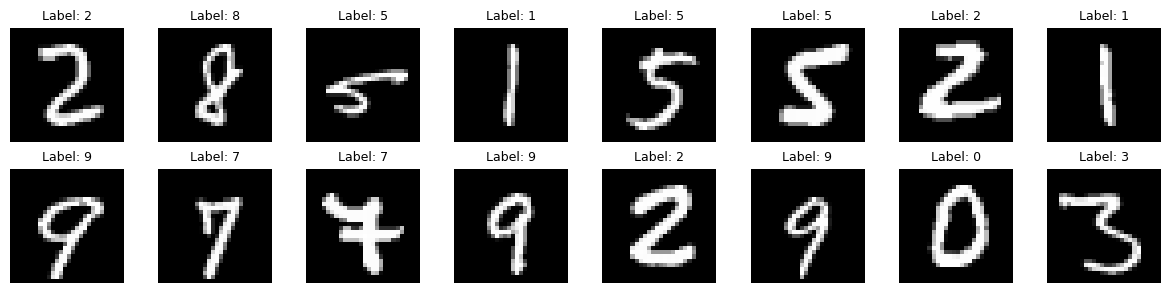

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset  = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")
print(f"Batches per epoch: {len(train_loader)}")

images, labels = next(iter(train_loader))

print(f"Batch image tensor shape: {images.shape}")  

fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(12, 3))
for idx, ax in enumerate(axes.flat):
    ax.imshow(images[idx].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[idx].item()}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [2]:
import torch.nn as nn

In [137]:

class VAE(nn.Module):
    def __init__(self):

        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Linear(784 , 400),
            nn.ReLU()
        )

        self.mu = nn.Linear(400,2)
        self.logvar = nn.Linear(400,2)

        self.decoder = nn.Sequential(
            nn.Linear(2 , 400),
            nn.ReLU(),
            nn.Linear(400 , 784),
        )

    def forward(self , x):

        encoder = self.encoder(x)

        mu = self.mu(encoder)
        logvar = self.logvar(encoder)

        eps = torch.randn_like(logvar)

        std = torch.exp(0.5 * logvar)
            
        z = mu + eps * std

        recon = self.decoder(z)

        return mu , logvar , recon , z
    

model = VAE()

In [138]:
import torch.nn.functional as F

In [139]:
def loss_fn(mu , logvar , x , x_recon):

    recon_loss = F.binary_cross_entropy_with_logits(input=x_recon , target=x , reduction='sum')
    
    kl_loss = -0.5 * torch.sum((logvar + 1 - mu ** 2 - torch.exp(logvar)))

    recon_loss /= batch_size 
    kl_loss /= batch_size

    return (recon_loss + kl_loss) / x.size(0)

In [140]:
learning_rate = 0.01

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [142]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X = X.reshape(-1 , 784)
        mu , logvar , recon , _ = model(X)
        loss = loss_fn(mu , logvar , X , recon)


        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss = 0

    with torch.no_grad():
        for X, y in dataloader:
            X = X.reshape(-1 , 784)
            mu , logvar , recon , _ = model(X)
            test_loss += loss_fn(mu , logvar , X , recon)
            
    test_loss /= num_batches
    print(f"Avg loss: {test_loss:>8f} \n")

In [143]:
for t in range(5):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer)
    test_loop(test_loader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 4.316987  [  128/60000]
loss: 1.404623  [12928/60000]
loss: 1.330873  [25728/60000]
loss: 1.298903  [38528/60000]
loss: 1.302044  [51328/60000]
Avg loss: 1.278309 

Epoch 2
-------------------------------
loss: 1.214685  [  128/60000]
loss: 1.266913  [12928/60000]
loss: 1.226048  [25728/60000]
loss: 1.194387  [38528/60000]
loss: 1.239833  [51328/60000]
Avg loss: 1.252133 

Epoch 3
-------------------------------
loss: 1.225844  [  128/60000]
loss: 1.221348  [12928/60000]
loss: 1.265296  [25728/60000]
loss: 1.240049  [38528/60000]
loss: 1.212797  [51328/60000]
Avg loss: 1.231813 

Epoch 4
-------------------------------
loss: 1.233713  [  128/60000]
loss: 1.174247  [12928/60000]
loss: 1.175332  [25728/60000]
loss: 1.232871  [38528/60000]
loss: 1.194594  [51328/60000]
Avg loss: 1.225935 

Epoch 5
-------------------------------
loss: 1.233214  [  128/60000]
loss: 1.220927  [12928/60000]
loss: 1.234115  [25728/60000]
loss: 1.206831  [38528/600

In [106]:
x = next(iter(test_loader))[0].reshape(128 , 784)
vae_recon = model(x)[2]

Text(0.5, 1.0, 'real')

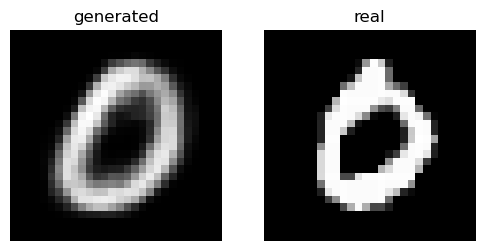

In [136]:
example = torch.sigmoid(vae_recon)[3].reshape(28,28)
fig , axes = plt.subplots(1 , 2 , figsize = (6,3))

axes[0].imshow(example.detach().numpy() , cmap = 'gray')
axes[1].imshow(x[3].reshape(28,28) , cmap = 'gray')

axes[0].axis('off')
axes[0].set_title('generated')

axes[1].axis('off')
axes[1].set_title('real')

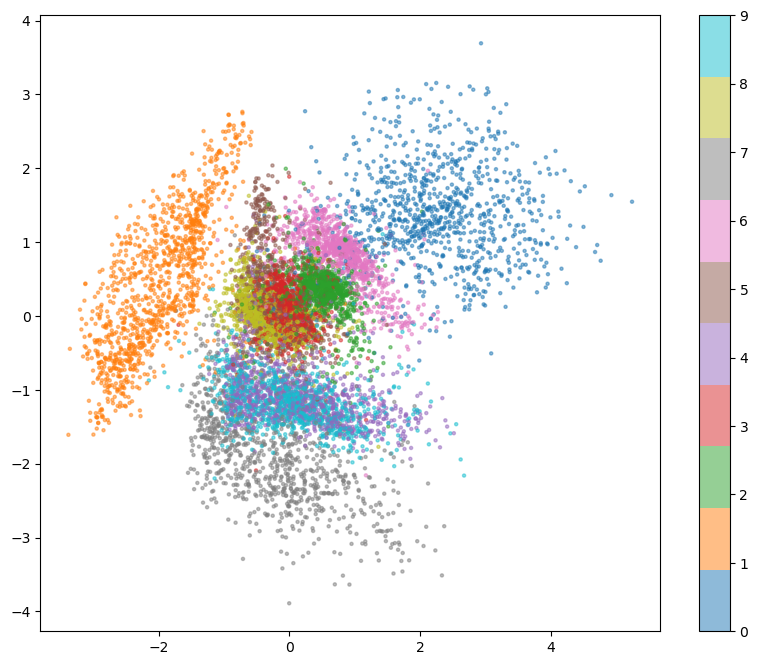

In [149]:
import matplotlib.pyplot as plt
import torch

def plot_latent_space(model, dataloader):
    model.eval()
    all_mu = []
    all_labels = []

    with torch.no_grad():
        for X, y in dataloader:
            X = X.view(-1, 784)
            mu, _, _  , _= model(X)
            all_mu.append(mu)
            all_labels.append(y)

    all_mu = torch.cat(all_mu, dim=0).numpy()
    all_labels = torch.cat(all_labels, dim=0).numpy()

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(all_mu[:, 0], all_mu[:, 1], c=all_labels, cmap='tab10', alpha=0.5, s=5)
    plt.colorbar(scatter)
    plt.show()

plot_latent_space(model, test_loader)


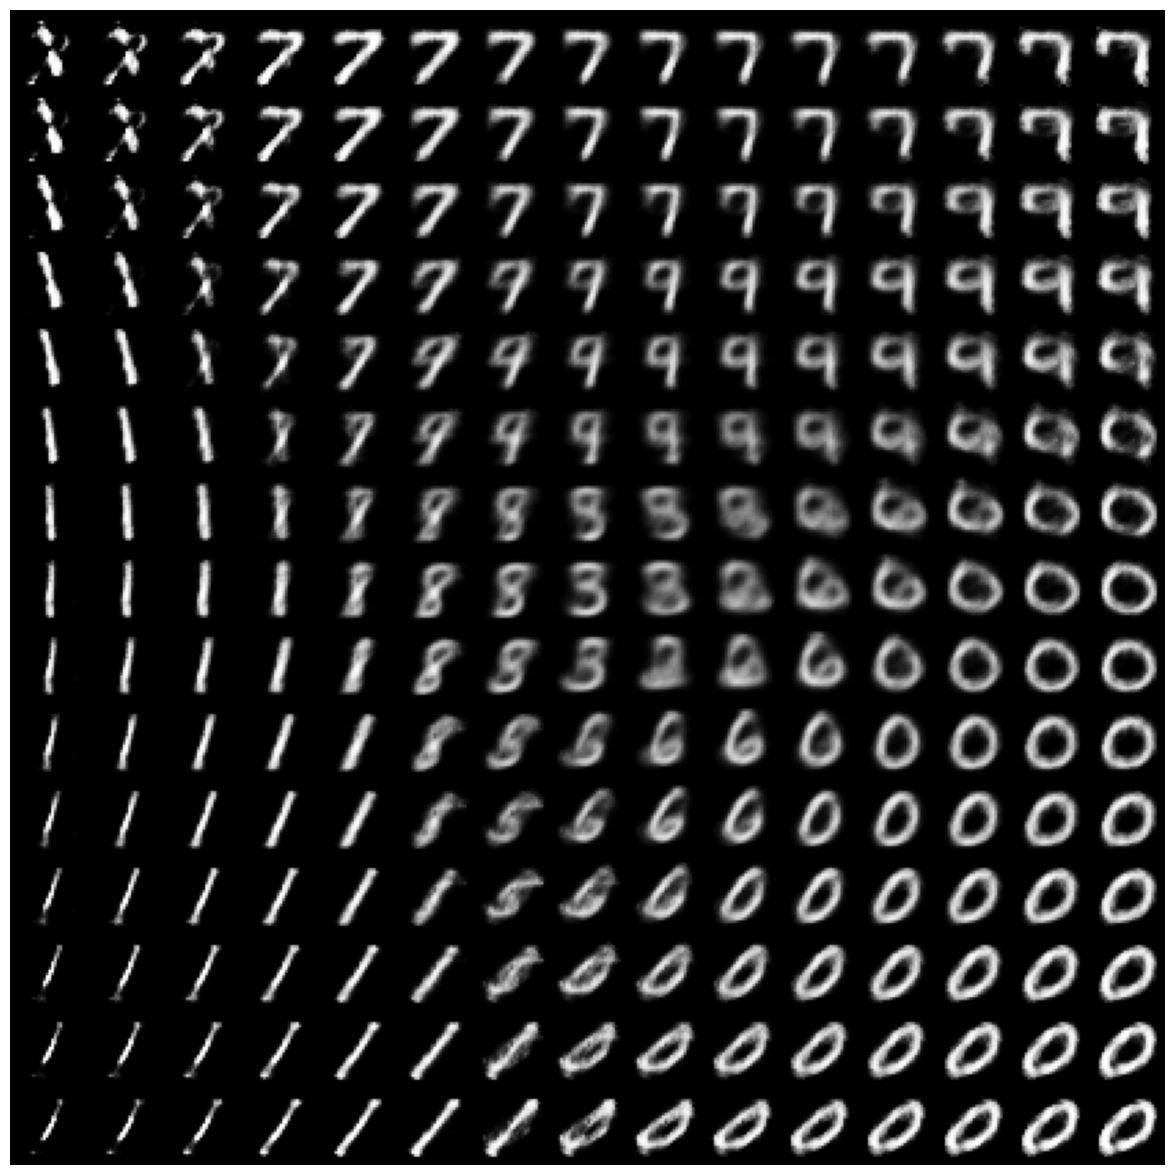

In [160]:
import numpy as np
def plot_latent_grid(model, n=15, figsize=15):
    model.eval()
    grid_x = np.linspace(-3, 3, n)
    grid_y = np.linspace(-3, 3, n)
    
    figure = np.zeros((28 * n, 28 * n))
    
    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z = torch.tensor([[xi, yi]], dtype=torch.float32)
                recon_logits = model.decoder(z)
        
                recon_probs = torch.sigmoid(recon_logits)
                
                digit = recon_probs.view(28, 28).cpu().numpy()
                figure[i * 28: (i + 1) * 28, j * 28: (j + 1) * 28] = digit

    plt.figure(figsize=(figsize, figsize))
    plt.imshow(figure, cmap='gray')
    plt.axis('off')
    plt.show()


plot_latent_grid(model)
